In [1]:
# Import + load .npz

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler

DATA_PROCESSED_DIR = "../data/processed"
LOOKBACK = 60
OUT_DIR = os.path.join(DATA_PROCESSED_DIR, f"datasets_close_OHLCV_L{LOOKBACK}")

TICKER = "BTC-USD"
H = 1
npz_path = os.path.join(OUT_DIR, f"{TICKER}_H{H}_targetClose_OHLCV.npz")

d = np.load(npz_path, allow_pickle=True)

X_train = d["X_train"]; y_train = d["y_train"]
X_val   = d["X_val"];   y_val   = d["y_val"]
X_test  = d["X_test"];  y_test  = d["y_test"]

train_dates = d["train_target_date"]
val_dates   = d["val_target_date"]
test_dates  = d["test_target_date"]

feature_cols = list(d["feature_cols"])
print("feature_cols:", feature_cols)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "y_val  :", y_val.shape)
print("X_test :", X_test.shape,  "y_test :", y_test.shape)
print("Test target range:", test_dates[0], "->", test_dates[-1])

feature_cols: ['Open', 'High', 'Low', 'Close', 'Volume']
X_train: (2032, 60, 5) y_train: (2032,)
X_val  : (435, 60, 5) y_val  : (435,)
X_test : (436, 60, 5) y_test : (436,)
Test target range: 2024-10-10 -> 2025-12-19


In [2]:
# Baseline naive (persistence): prediksi = Close terakhir di window

# scaler untuk X (fit di train) disimpan di npz
x_mean = d["scaler_mean"]      # shape (5,)
x_scale = d["scaler_scale"]    # shape (5,)

# cari index fitur Close
close_idx = feature_cols.index("Close")

def unscale_feature(x_scaled, feat_idx):
    return x_scaled * x_scale[feat_idx] + x_mean[feat_idx]

# naive pred = last close dari window input
yhat_test_naive = unscale_feature(X_test[:, -1, close_idx], close_idx)

def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y_pred - y_true)**2)))

def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    return 100.0 * np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps))

naive_metrics = {
    "test_MAE_naive": float(np.mean(np.abs(y_test - yhat_test_naive))),
    "test_RMSE_naive": rmse(y_test, yhat_test_naive),
    "test_sMAPE_naive": smape(y_test, yhat_test_naive),
}
naive_metrics

{'test_MAE_naive': 1612.3997813933486,
 'test_RMSE_naive': 2197.0622038664146,
 'test_sMAPE_naive': np.float64(1.6686958751101333)}

In [3]:
# Scale target y (recommended)

y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train.reshape(-1,1)).reshape(-1)
y_val_s   = y_scaler.transform(y_val.reshape(-1,1)).reshape(-1)
y_test_s  = y_scaler.transform(y_test.reshape(-1,1)).reshape(-1)

In [4]:
# Model Attention-LSTM (temporal attention)

def build_attention_lstm(input_shape, lstm_units=64, dropout=0.2, lr=1e-3):
    inp = layers.Input(shape=input_shape)  # (lookback, n_features)

    x = layers.LSTM(lstm_units, return_sequences=True)(inp)
    x = layers.Dropout(dropout)(x)

    score = layers.Dense(1)(x)  # (batch, time, 1)
    weights = layers.Softmax(axis=1, name="attn_weights")(score)

    context = layers.Multiply()([x, weights])
    context = layers.Lambda(lambda t: tf.reduce_sum(t, axis=1), name="context")(context)

    out = layers.Dense(32, activation="relu")(context)
    out = layers.Dense(1, name="y_hat")(out)

    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.Huber(),   # lebih robust dari MSE
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

tf.keras.utils.set_random_seed(42)

model = build_attention_lstm(
    input_shape=X_train.shape[1:],  # (60, 5)
    lstm_units=64,
    dropout=0.2,
    lr=1e-3
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 60, 5)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 60, 64)    │     17,920 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 60, 64)    │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 60, 1)     │         65 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_weights        │ (None, 60, 1)     │          0 │ dense[0][0]       │
│ (Softmax)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 60, 64)    │          0 │ dropout[0][0],    │
│                     │                   │            │ attn_weights[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context (Lambda)    │ (None, 64)        │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ context[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ y_hat (Dense)       │ (None, 1)         │         33 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 20,098 (78.51 KB)

 Trainable params: 20,098 (78.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.1966 - mae: 0.4798 - val_loss: 0.6336 - val_mae: 1.0649 - learning_rate: 0.0010
Epoch 2/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0937 - mae: 0.2815 - val_loss: 0.2355 - val_mae: 0.5819 - learning_rate: 0.0010
Epoch 3/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0576 - mae: 0.2544 - val_loss: 0.3186 - val_mae: 0.7039 - learning_rate: 0.0010
Epoch 4/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0625 - mae: 0.2674 - val_loss: 0.2735 - val_mae: 0.6430 - learning_rate: 0.0010
Epoch 5/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0561 - mae: 0.2482 - val_loss: 0.2791 - val_mae: 0.6494 - learning_rate: 0.0010
Epoch 6/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0545 - mae: 0.2367 - val_loss: 0.3083 - val_mae: 0.6870 - learning_rate: 0.0010
Epoch 7/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0529 - mae: 0.2196 - val_loss: 0.2237 - val_mae: 0.5692 - learning_rate: 0.0010
Epoch 

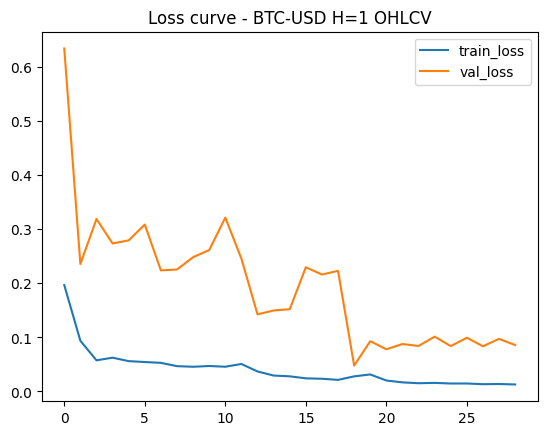

In [5]:
# Train

callbacks = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)
]

history = model.fit(
    X_train, y_train_s,
    validation_data=(X_val, y_val_s),
    epochs=100,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

plt.figure()
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.title(f"Loss curve - {TICKER} H={H} OHLCV")
plt.show()

In [6]:
# Evaluate (inverse ke harga asli) + bandingkan dengan baseline

# pred (scaled)
yhat_test_s = model.predict(X_test).reshape(-1)

# inverse to price
yhat_test = y_scaler.inverse_transform(yhat_test_s.reshape(-1,1)).reshape(-1)

model_metrics = {
    "test_MAE_model": float(np.mean(np.abs(y_test - yhat_test))),
    "test_RMSE_model": rmse(y_test, yhat_test),
    "test_sMAPE_model": smape(y_test, yhat_test),
}
model_metrics

compare = {**naive_metrics, **model_metrics}
compare


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


{'test_MAE_naive': 1612.3997813933486,
 'test_RMSE_naive': 2197.0622038664146,
 'test_sMAPE_naive': np.float64(1.6686958751101333),
 'test_MAE_model': 24019.054123064794,
 'test_RMSE_model': 26316.548379164684,
 'test_sMAPE_model': np.float64(26.691751294638095)}

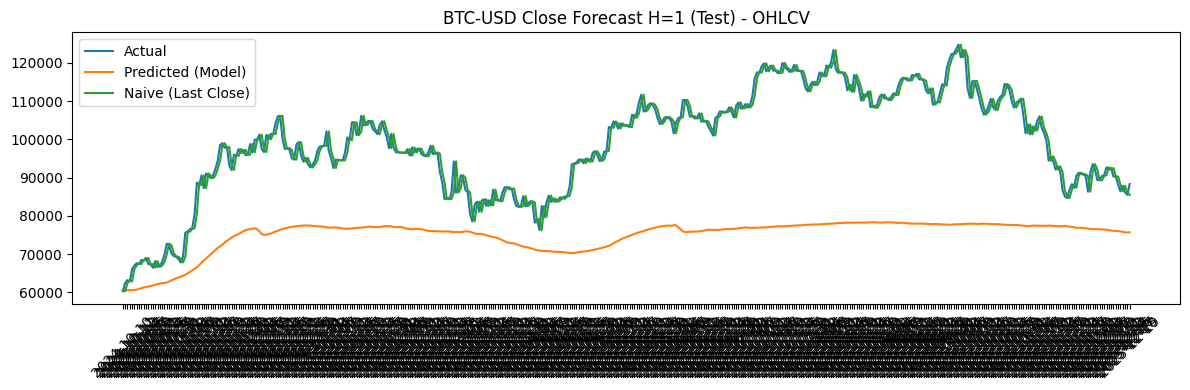

In [9]:
# Plot prediksi vs aktual (test)

plt.figure(figsize=(12,4))
plt.plot(test_dates, y_test, label="Actual")
plt.plot(test_dates, yhat_test, label="Predicted (Model)")
plt.plot(test_dates, yhat_test_naive, label="Naive (Last Close)")
plt.xticks(rotation=45)
plt.title(f"{TICKER} Close Forecast H={H} (Test) - OHLCV")
plt.legend()
plt.tight_layout()
plt.show()